# Assignment 4 – Analyzing Weather Data from OpenWeatherMap API

In [1]:
import requests
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Fetch Data from OpenWeatherMap API

In [2]:
# --- CONFIGURATION ---
API_KEY  = '5456689f32bdc4b8d37eeaaa9e190187'   # Replace with your actual key
CITY     = 'Pune'
UNITS    = 'metric'
BASE_URL = 'https://api.openweathermap.org/data/2.5/forecast'

params = {'q': CITY, 'appid': API_KEY, 'units': UNITS, 'cnt': 40}

response = requests.get(BASE_URL, params=params)
if response.status_code == 200:
    raw_data = response.json()
    print('API call successful')
else:
    print("API key is not working")
    quit()

API call successful


## 2. Extract Relevant Attributes

In [3]:
records = []
for entry in raw_data['list']:
    records.append({
        'datetime':    entry['dt_txt'],
        'temp':        entry['main']['temp'],
        'feels_like':  entry['main']['feels_like'],
        'temp_min':    entry['main']['temp_min'],
        'temp_max':    entry['main']['temp_max'],
        'humidity':    entry['main']['humidity'],
        'pressure':    entry['main']['pressure'],
        'wind_speed':  entry['wind']['speed'],
        'clouds':      entry['clouds']['all'],
        'weather':     entry['weather'][0]['main'],
        'description': entry['weather'][0]['description'],
        'rain_3h':     entry.get('rain', {}).get('3h', 0)
    })

df = pd.DataFrame(records)
df['datetime'] = pd.to_datetime(df['datetime'])
df['date']     = df['datetime'].dt.date
df['hour']     = df['datetime'].dt.hour

print(df.shape)
df.head(4)

(40, 14)


,datetime,temp,feels_like,temp_min,temp_max,humidity,pressure,wind_speed,clouds,weather,description,rain_3h,date,hour
0,2026-11-02 15:00:00,23.76,23.78,22.74,23.76,61,1014,0.68,78,Rain,light rain,2.99,2026-11-02,15
1,2026-11-02 18:00:00,24.38,24.88,24.38,24.43,77,1015,0.93,56,Rain,light rain,2.14,2026-11-02,18
2,2026-11-02 21:00:00,22.08,22.54,22.08,22.08,84,1014,0.60,83,Rain,light rain,0.33,2026-11-02,21
3,2026-11-03 00:00:00,21.74,22.16,21.74,21.74,84,1014,0.92,74,Clouds,broken clouds,0.00,2026-11-03,0


## 3. Clean & Preprocess

In [4]:
print('Missing values:')
print(df.isnull().sum())

df['rain_3h'] = df['rain_3h'].fillna(0)
print('\nData types:\n', df.dtypes)

Missing values:
datetime       0
temp           0
feels_like     0
temp_min       0
temp_max       0
humidity       0
pressure       0
wind_speed     0
clouds         0
weather        0
description    0
rain_3h        0
date           0
hour           0
dtype: int64

Data types:
 datetime       datetime64[ns]
temp                  float64
feels_like            float64
temp_min              float64
temp_max              float64
humidity                int64
pressure                int64
wind_speed            float64
clouds                  int64
weather                object
description            object
rain_3h               float64
date                   object
hour                    int32
dtype: object


## 4. Data Modeling – Averages, Min/Max, Trends

In [5]:
daily = df.groupby('date').agg(
    avg_temp   = ('temp',       'mean'),
    max_temp   = ('temp_max',   'max'),
    min_temp   = ('temp_min',   'min'),
    avg_humidity = ('humidity', 'mean'),
    total_rain = ('rain_3h',    'sum'),
    avg_wind   = ('wind_speed', 'mean')
).reset_index()

daily

,date,avg_temp,max_temp,min_temp,avg_humidity,total_rain,avg_wind
0,2026-11-02,23.406667,24.43,22.08,74.000,5.46,0.736667
1,2026-11-03,26.431250,30.70,21.74,60.625,0.00,1.512500
2,2026-11-04,26.486250,31.16,22.89,59.375,0.10,1.991250
3,2026-11-05,26.483750,31.29,22.96,53.875,0.00,2.073750
4,2026-11-06,26.718750,31.06,22.32,44.000,0.00,2.112500
5,2026-11-07,26.672000,30.49,21.53,35.200,0.00,2.640000


## 5. Visualisations

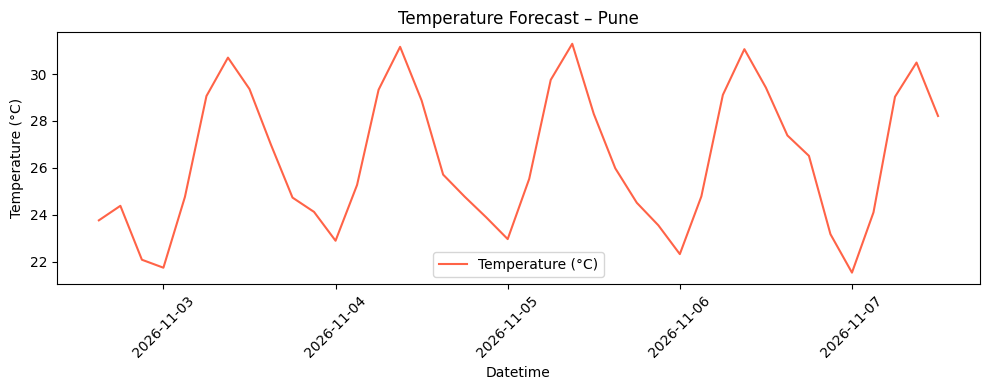

In [15]:
# Temperature over time
plt.figure(figsize=(10, 4))
plt.plot(df['datetime'], df['temp'], label='Temperature (°C)', color='tomato')
plt.xlabel('Datetime')
plt.ylabel('Temperature (°C)')
plt.title(f'Temperature Forecast – {CITY}')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

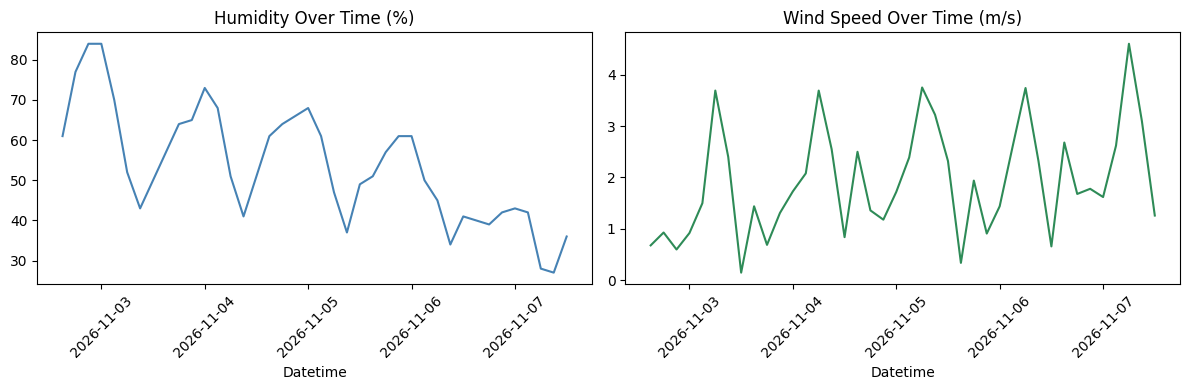

In [7]:
# Humidity & Wind speed
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df['datetime'], df['humidity'], color='steelblue')
axes[0].set_title('Humidity Over Time (%)')
axes[0].set_xlabel('Datetime')
axes[0].tick_params(axis='x', rotation=45)

axes[1].plot(df['datetime'], df['wind_speed'], color='seagreen')
axes[1].set_title('Wind Speed Over Time (m/s)')
axes[1].set_xlabel('Datetime')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

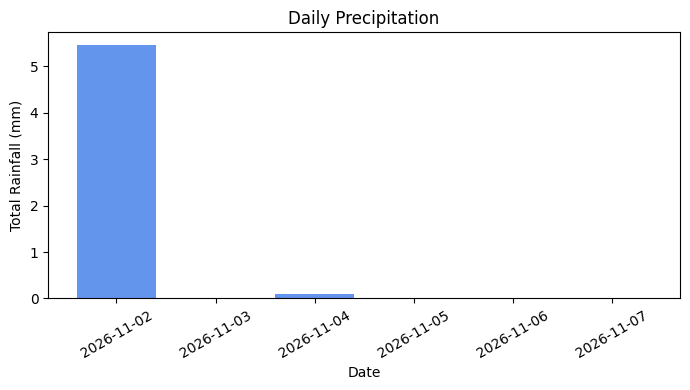

In [8]:
# Daily precipitation bar chart
plt.figure(figsize=(7, 4))
plt.bar([str(d) for d in daily['date']], daily['total_rain'], color='cornflowerblue')
plt.xlabel('Date')
plt.ylabel('Total Rainfall (mm)')
plt.title('Daily Precipitation')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 6. Aggregation by Time Period

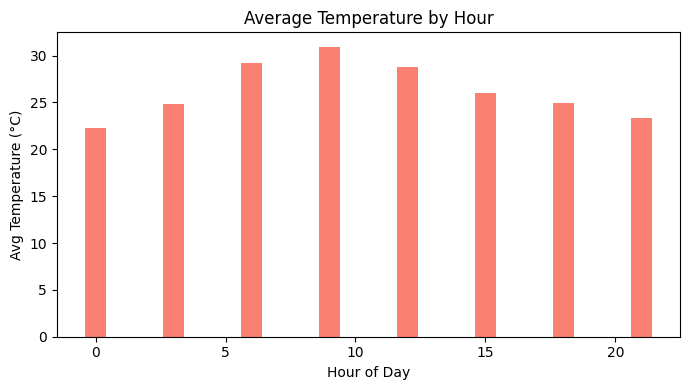

In [9]:
# Hourly average temperature pattern
hourly_avg = df.groupby('hour')['temp'].mean()

plt.figure(figsize=(7, 4))
plt.bar(hourly_avg.index, hourly_avg.values, color='salmon')
plt.xlabel('Hour of Day')
plt.ylabel('Avg Temperature (°C)')
plt.title('Average Temperature by Hour')
plt.tight_layout()
plt.show()

## 7. Correlation – Temperature vs Humidity

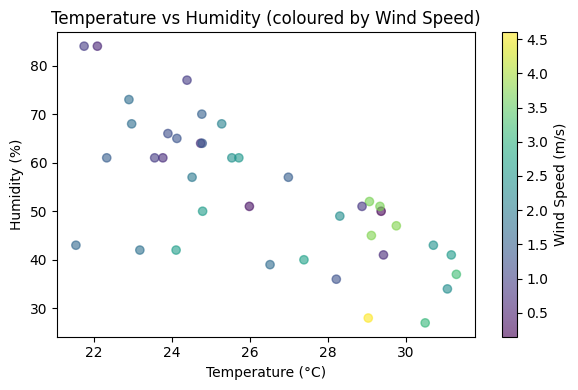

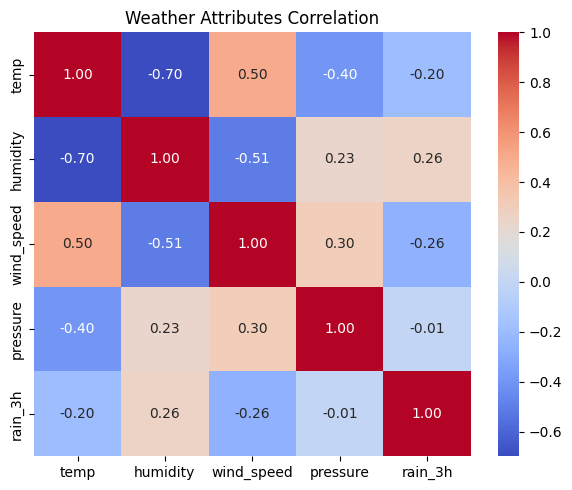

In [10]:
plt.figure(figsize=(6, 4))
plt.scatter(df['temp'], df['humidity'], alpha=0.6, c=df['wind_speed'], cmap='viridis')
plt.colorbar(label='Wind Speed (m/s)')
plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')
plt.title('Temperature vs Humidity (coloured by Wind Speed)')
plt.tight_layout()
plt.show()

corr_matrix = df[['temp', 'humidity', 'wind_speed', 'pressure', 'rain_3h']].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Weather Attributes Correlation')
plt.tight_layout()
plt.show()